# Lab 8 - Bayesian Logistic Regression and Bootstrapping

Today, we will examine how to move beyond single-point estimates in machine learning by exploring the Bayesian interpretation of model parameters and how to handle the computational challenges that arise in classification.

More specifically, in the Bayesian interpretation, we treat the parameters of the model $\mathbf{w}$ as random variables.  
We want to learn their full posterior distribution, $p(\mathbf{w} \mid \mathcal{D})$:

$$p(\mathbf{w} \mid \mathcal{D}) = \frac{p(\mathcal{D} \mid \mathbf{w}) p(\mathbf{w})}{p(\mathcal{D})} = \frac{p(\mathcal{D} \mid \mathbf{w}) p(\mathbf{w})}{\int_{\mathbb{R}^D} p(\mathcal{D} \mid \mathbf{w}') p(\mathbf{w}') \, d\mathbf{w}'}$$

Where:

- **Prior** $p(\mathbf{w})$: what we believe about the parameters *before* seeing any data.
- **Likelihood** $p(\mathcal{D} \mid \mathbf{w})$: how probable the observed data $\mathcal{D}$ is for a fixed value of the parameters $\mathbf{w}$. It tells us how well a given $\mathbf{w}$ explains the data.
- **Evidence** (or marginal likelihood) $p(\mathcal{D}) = \int_{\mathbb{R}^D} p(\mathcal{D} \mid \mathbf{w}') p(\mathbf{w}') \, d\mathbf{w}'$: the probability of the data averaged over all possible parameters, weighted by the prior..
- **Posterior** $p(\mathbf{w} \mid \mathcal{D})$: our updated belief about $\mathbf{w}$ after observing the data.

The intuition is that we have a prior distribution $p(\mathbf{w})$ over potential values of $\mathbf{w}$, and we want to find the posterior distribution $p(\mathbf{w} \mid \mathcal{D})$ after observing the data.

In this lab we will focus on Bayesian logistic regression, in which the  **evidence** is usually difficult to compute $p(\mathcal{D})$.  
Instead, we will study two main methods to resolve this problem:

1. **Approximate Bayesian Inference** using MCMC, a way to aproximate posterior distributions
2. **Bootstrapping**, a way to obain an empirical distribution of the weights

# Recap
## Logistic regression, maximum likelihood estimation
We are given a training dataset $\mathcal{D}=\{(\mathbf{x}_n,y_n)\}_{n=1}^N$ with $N$ examples.  
Each example consists of a feature vector $\mathbf{x}_n\in\mathbb{R}^d$ and a binary label $y_n\in\{0,1\}$.    
Our goal is to learn model, i.e., a weight vector $\mathbf{w}\in\mathbb{R}^d$ that lets us predict the label of a new input $\mathbf{x}$.

Binary logistic regression applies the sigmoid function to the linear score $\mathbf{w}^{\top}\mathbf{x}$ to obtain the probability of class $1$.

$$
p(y=1\mid\mathbf{x},\mathbf{w})
=
\sigma(\mathbf{w}^{\top}\mathbf{x}),
\qquad
\sigma(z)=\frac{1}{1+e^{-z}}.
$$

The probability of class $0$ is $p(y=0\mid\mathbf{x},\mathbf{w}) = 1 - p(y=1\mid\mathbf{x},\mathbf{w}) = 1-\sigma(\mathbf{w}^{\top}\mathbf{x})$.   
Assuming the labels are conditionally independent given the inputs and weights, the likelihood is the product of the probabilities assigned to the observed labels.

$$
\begin{aligned}
p(\mathcal{D}\mid\mathbf{w})
&= \prod_{n=1}^N p(y_n\mid\mathbf{x}_n,\mathbf{w}) = \prod_{n=1}^N
\sigma(\mathbf{w}^{\top}\mathbf{x}_n)^{y_n}
\bigl[1-\sigma(\mathbf{w}^{\top}\mathbf{x}_n)\bigr]^{1-y_n}.
\end{aligned}
$$

**Maximum likelihood estimation (MLE)** chooses the weights that maximize the likelihood:
$$w_{MLE} = arg\max_w p(\mathcal{D}\mid\mathbf{w}) $$
Equivalently, it minimizes the negative log-likelihood, which is the sum of the binary cross-entropy losses.

$$
\mathcal{L}(\mathbf{w})
=
-\sum_{n=1}^N
\left[
y_n\log \sigma(\mathbf{w}^{\top}\mathbf{x}_n)
+
(1-y_n)\log\bigl(1-\sigma(\mathbf{w}^{\top}\mathbf{x}_n)\bigr)
\right].
$$

**Gradient descent** updates the weights by subtracting the gradient of the loss scaled by a learning rate $\eta>0$.

$$
\mathbf{w}\leftarrow\mathbf{w}-\eta\nabla_{\mathbf{w}}\mathcal{L}(\mathbf{w}),
\qquad
\nabla_{\mathbf{w}}\mathcal{L}(\mathbf{w})
=
\sum_{n=1}^N
\bigl[\sigma(\mathbf{w}^{\top}\mathbf{x}_n)-y_n\bigr]\mathbf{x}_n.
$$

MLE gives a **single** weight vector.

## Data

We will use a synthetic dataset for binary classification. Each example has two features, $\mathbf{x}_n=(x_{n,1},x_{n,2})\in\mathbb{R}^2$, and a label $y_n\in\{0,1\}$.


In [5]:
# to install the library, run this!
%pip install numpyro

/opt/homebrew/Cellar/python@3.11/3.11.6_1/Frameworks/Python.framework/Versions/3.11/lib/python3.11/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()



[notice] A new release of pip is available: 23.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


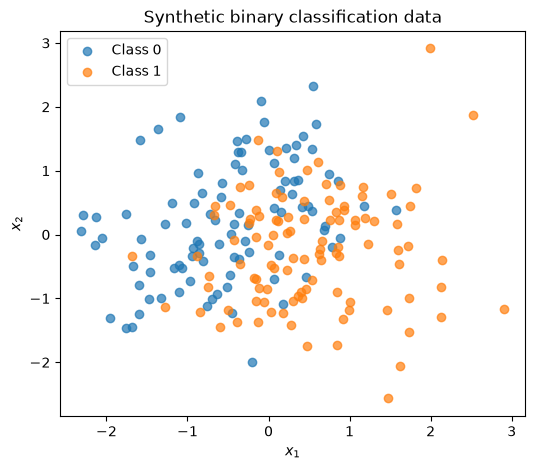

In [6]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Generate 200 observations with two features each.
n_samples = 200
X = rng.normal(size=(n_samples, 2))

# Use a known weight vector to generate class probabilities.
w_true = np.array([1.5, -1.0])
scores = X @ w_true
probabilities = 1 / (1 + np.exp(-scores))

# Draw one binary label per observation.
y = rng.binomial(n=1, p=probabilities)

fig, ax = plt.subplots(figsize=(6, 5))

for label in (0, 1):
    mask = y == label
    ax.scatter(X[mask, 0], X[mask, 1], label=f"Class {label}", alpha=0.7)

ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Synthetic binary classification data")
ax.legend()
plt.show()

### Bayesian logistic regression with MCMC
The likelihood, $p(\mathcal{D}\mid\mathbf{w})$, measures how well a given parameter vector $\mathbf{w}$ explains the observed data.

Today, we will look at the posterior distribution of the parameters, $p(\mathbf{w} \mid \mathcal{D})$, which describes how plausible different parameter values are, given the observed data and our prior beliefs:
$$p(\mathbf{w} \mid \mathcal{D}) = \frac{p(\mathcal{D} \mid \mathbf{w}) p(\mathbf{w})}{p(\mathcal{D})} = \frac{p(\mathcal{D} \mid \mathbf{w}) p(\mathbf{w})}{\int_{\mathbb{R}^D} p(\mathcal{D} \mid \mathbf{w}') p(\mathbf{w}') \, d\mathbf{w}'}$$

When the parameters are continuous, the denominator involves an integral that can be difficult to compute. In such cases, we often use approximate inference methods to approximate the posterior distribution.

We will use Markov chain Monte Carlo (MCMC) for **approximate Bayesian
inference**.   

MCMC is a family of algorithms designed to get samples $w^1,w^2,\cdots,w^n$ from an intractable posterior distribution $p(\mathbf{w}\mid\mathcal{D})$.

MCMC can target the posterior using the product of the
likelihood and the prior, without evaluating the evidence $p(\mathcal{D})$:

$$
p(\mathbf{w}\mid\mathcal{D})
\propto p(\mathcal{D}\mid\mathbf{w})\,p(\mathbf{w}).
$$

Starting from an initial weight vector $\mathbf{w}^{(0)}$, MCMC generates
a sequence $\mathbf{w}^{(0)},\mathbf{w}^{(1)},\mathbf{w}^{(2)},\ldots$.  
Each new weight vector $\mathbf{w}^{(t+1)}$ depends on the current one
$\mathbf{w}^{(t)}$.   
The transitions are designed so that, over a long run,
the fraction of draws in a region approximates its posterior probability.

After warm-up, we use the retained weight vectors to approximate the
posterior. The example below shows how to run this procedure in NumPyro.

In [7]:
import jax.numpy as jnp
from jax import random
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS


def logistic_regression(X, y):
    # Independent standard Gaussian priors on the weights.
    w = numpyro.sample("w", dist.Normal(0, 1).expand([X.shape[1]]).to_event(1))

    # The probability of class 1 is sigmoid(X @ w).
    with numpyro.plate("observations", X.shape[0]):
        numpyro.sample("y_obs", dist.Bernoulli(logits=X @ w), obs=y)


mcmc = MCMC(
    NUTS(logistic_regression),
    num_warmup=1_000,
    num_samples=1_000,
    num_chains=4,
    chain_method="sequential",
)
mcmc.run(random.key(42), jnp.asarray(X), jnp.asarray(y))

print("True weights:", w_true)
mcmc.print_summary(prob=0.95)

# Shape: (4000, 2), with the 4 chains of 1000 samples combined.
w_samples = mcmc.get_samples()["w"]

sample: 100%|██████████| 2000/2000 [00:00<00:00, 8315.59it/s, 7 steps of size 7.07e-01. acc. prob=0.93]


True weights: [ 1.5 -1. ]

                mean       std    median      2.5%     97.5%     n_eff     r_hat
      w[0]      1.68      0.24      1.67      1.21      2.17   2066.05      1.00
      w[1]     -0.94      0.21     -0.94     -1.39     -0.53   2080.64      1.00

Number of divergences: 0


In [8]:
w_samples

Array([[ 1.3216444 , -0.78738296],
       [ 1.7286491 , -1.046374  ],
       [ 1.8461105 , -1.0859303 ],
       ...,
       [ 1.7804058 , -0.66569734],
       [ 1.4795761 , -0.55243737],
       [ 1.7145689 , -0.83147675]], dtype=float32)

In [9]:
w_samples.shape

(4000, 2)

Posterior mean: [ 1.6807934  -0.94429237]
True weights: [ 1.5 -1. ]


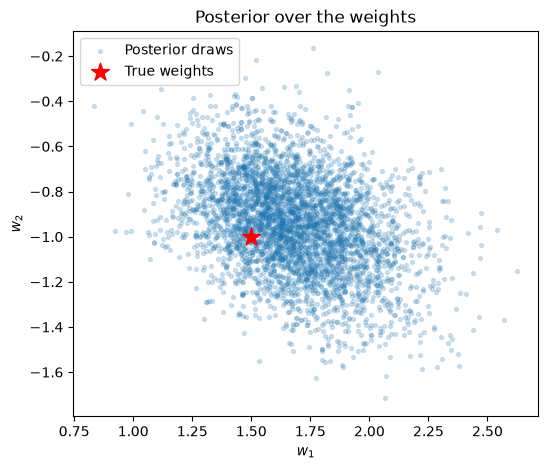

In [10]:
import numpy as np
import matplotlib.pyplot as plt

weights = np.asarray(w_samples)

print("Posterior mean:", weights.mean(axis=0))
print("True weights:", w_true)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(weights[:, 0], weights[:, 1], s=8, alpha=0.2, label="Posterior draws")
ax.scatter(*w_true, color="red", marker="*", s=180, label="True weights")
ax.set(xlabel="$w_1$", ylabel="$w_2$", title="Posterior over the weights")
ax.legend()
plt.show()

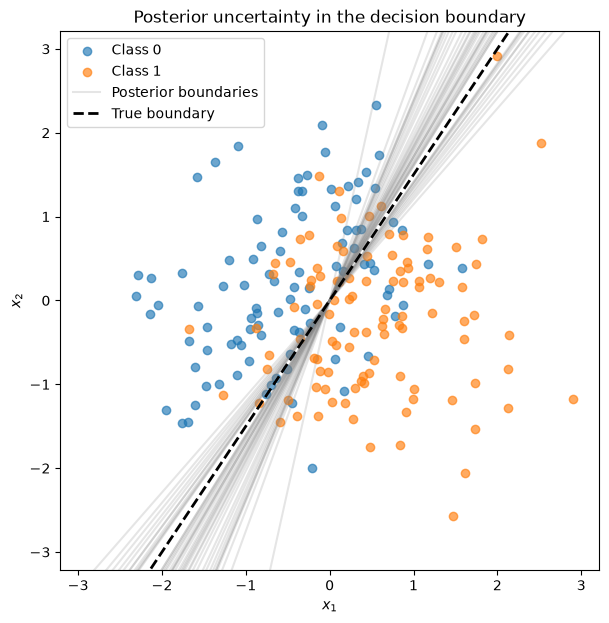

In [11]:
import numpy as np
import matplotlib.pyplot as plt

weights = np.asarray(w_samples)
rng = np.random.default_rng(42)
draw_indices = rng.choice(len(weights), size=40, replace=False)

limit = np.abs(X).max() + 0.3
t = np.array([-1, 1]) * np.sqrt(2) * limit

fig, ax = plt.subplots(figsize=(7, 7))

for label in (0, 1):
    mask = y == label
    ax.scatter(X[mask, 0], X[mask, 1], label=f"Class {label}", alpha=0.65)


def plot_boundary(w, **kwargs):
    # The line runs in a direction perpendicular to w.
    direction = np.array([-w[1], w[0]]) / np.linalg.norm(w)
    line = t[:, None] * direction
    ax.plot(line[:, 0], line[:, 1], **kwargs)


for i, draw_index in enumerate(draw_indices):
    plot_boundary(
        weights[draw_index],
        color="gray",
        alpha=0.2,
        label="Posterior boundaries" if i == 0 else None,
    )

plot_boundary(w_true, color="black", linestyle="--", linewidth=2,
              label="True boundary")

ax.set(
    xlim=(-limit, limit),
    ylim=(-limit, limit),
    xlabel="$x_1$",
    ylabel="$x_2$",
    title="Posterior uncertainty in the decision boundary",
)
ax.set_aspect("equal")
ax.legend()
plt.show()

# **Marginal Model.**   
For a fixed new input
$\mathbf{x}_{\mathrm{new}}$, we use the law of total probability to
average over the unknown weights:

$$
\begin{aligned}
p(y_{\mathrm{new}}=1\mid\mathbf{x}_{\mathrm{new}},\mathcal{D})
&=
\int
p(y_{\mathrm{new}}=1\mid\mathbf{x}_{\mathrm{new}},\mathbf{w})\,
p(\mathbf{w}\mid\mathcal{D})\,d\mathbf{w}=
\int
\sigma(\mathbf{w}^{\top}\mathbf{x}_{\mathrm{new}})\,
p(\mathbf{w}\mid\mathcal{D})\,d\mathbf{w}.
\end{aligned}
$$

Having $S$ posterior draws
$\mathbf{w}^{(1)},\ldots,\mathbf{w}^{(S)}$, we approximate it by

$$
p(y_{\mathrm{new}}=1\mid\mathbf{x}_{\mathrm{new}},\mathcal{D})
\approx \frac{1}{S}\sum_{s=1}^{S}p(y_{\mathrm{new}}=1\mid\mathbf{x}_{\mathrm{new}},\mathbf{w}^s) \approx
\frac{1}{S}\sum_{s=1}^{S}
\sigma\bigl((\mathbf{w}^{(s)})^\top\mathbf{x}_{\mathrm{new}}\bigr).
$$



#### Some notes on uncertainty

**Model uncertainty**, or **epistemic uncertainty**, describes how uncertain we are about the model’s parameters. In Bayesian inference, this is represented by the posterior distribution $p(\mathbf{w}\mid\mathcal{D})$. A posterior concentrated in a small region indicates low parameter uncertainty, while a broadly spread posterior indicates greater uncertainty.

**Data uncertainty**, or **aleatoric uncertainty**, describes the uncertainty about the label $y_{\mathrm{new}}$ for a given input $\mathbf{x}_{\mathrm{new}}$, even when the model’s weights are known. It is represented by the conditional distribution $p(y_{\mathrm{new}}\mid\mathbf{x}_{\mathrm{new}},\mathbf{w})$. For example, if
$$
p(y_{\mathrm{new}}=1\mid\mathbf{x}_{\mathrm{new}},\mathbf{w})=0.5,
$$
the model assigns equal probability to labels $0$ and $1$, even for this fixed weight vector.

The **marginal model**, accounts for both sources of uncertainty by averaging the label probabilities over the posterior distribution of the weights:
$$
p(y_{\mathrm{new}}=1\mid\mathbf{x}_{\mathrm{new}},\mathcal{D})
=
\int_{\mathbb{R}^D}
p(y_{\mathrm{new}}=1\mid\mathbf{x}_{\mathrm{new}},\mathbf{w})
\,p(\mathbf{w}\mid\mathcal{D})\,d\mathbf{w}.
$$

In [16]:
x_new = np.array([1.0, 0.5])

scores = weights @ x_new
probability_draws = 1 / (1 + np.exp(-scores))
probability_draws

array([0.7166598 , 0.76949505, 0.78636385, ..., 0.80962218, 0.76912151,
       0.78563809], shape=(4000,))

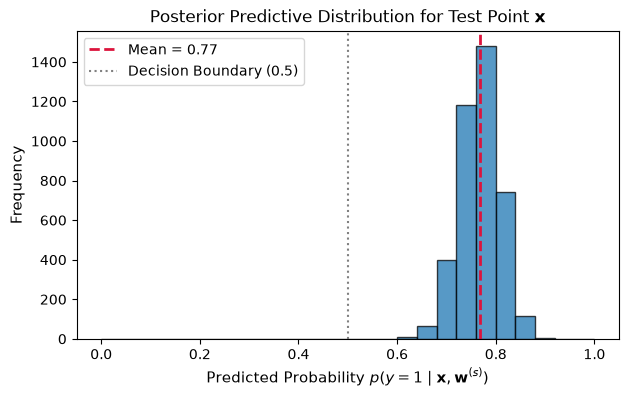

In [17]:
plt.figure(figsize=(7, 4))
plt.hist(probability_draws, bins=25, range=(0, 1), edgecolor='black', alpha=0.75)

# Add informative title and axis labels
plt.title('Posterior Predictive Distribution for Test Point $\mathbf{x}$', fontsize=12)
plt.xlabel('Predicted Probability $p(y = 1 \mid \mathbf{x}, \mathbf{w}^{(s)})$', fontsize=11)
plt.ylabel('Frequency', fontsize=11)

# Optional: Add reference lines for the mean prediction and the 0.5 decision threshold
plt.axvline(probability_draws.mean(), color='crimson', linestyle='--', linewidth=2, label=f'Mean = {probability_draws.mean():.2f}')
plt.axvline(0.5, color='gray', linestyle=':', linewidth=1.5, label='Decision Boundary (0.5)')
plt.legend()

plt.show()
plt.close()

In [18]:
predictive_probability = probability_draws.mean()
print(f"Predictive uncertenty: {predictive_probability:.3f}")

Predictive uncertenty: 0.768


## B. Bootstrapping

Bootstrapping gives us another way to quantify uncertainty about the
weights.  
It estimates how much the fitted weights would vary if we
trained the model on different datasets of the same size.

Starting from the original dataset $\mathcal{D}$ with $N$ examples,
we create $S$ bootstrap datasets
$\mathcal{D}^{(1)},\ldots,\mathcal{D}^{(S)}$ by drawing $N$ examples
with replacement from $\mathcal{D}$.

For each bootstrap dataset $\mathcal{D}^{(s)}$, we can fit logistic regression
using maximum likelihood to obtain a weight vector $\widehat{\mathbf{w}}^{(s)}$.  
Repeating this for each bootstrap dataset $\mathcal{D}^{(s)}$ gives us a set of possible weight vectors.

Under enough data and a correctly
specified model, the distribution of the bootstrap weights and the
Bayesian posterior $p(\mathbf{w}\mid\mathcal{D})$ can have similar shapes.

### Implementation

1. **Generate $S = 30$ bootstrap datasets.** For each dataset, draw $N$ examples with replacement from $\mathcal{D}$, keeping each feature vector and its label together.

2. **Fit a logistic regression model on each bootstrap dataset.** Use an model without an intercept.

   ```python
   clf = LogisticRegression(fit_intercept=False, C=1.0)
   ```


3. **Collect weights.** After fitting each model, get its weight vector from `clf.coef_[0]`. This gives you $S$ weight vectors, one per bootstrap dataset.

4. **Compare the weight distributions.** Plot the bootstrap weight vectors and the MCMC posterior draws in the $(w_1,w_2)$ plane.